# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
file_path = '/hpc/group/hickeylab/fl135/pkl_data/DLPFC_151673_overlap=100__pseudocount_0_spotIndex.h5'

ad_ = sc.read_h5ad(file_path)

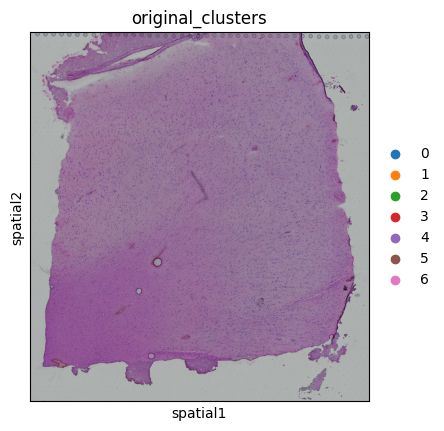

In [5]:
sc.pl.spatial(ad_, color='original_clusters', spot_size=1.5)

In [6]:
file_path = '/hpc/group/hickeylab/fl135/pkl_data/DLPFC_151673original_spotIndex.h5'

ad_target = sc.read_h5ad(file_path)


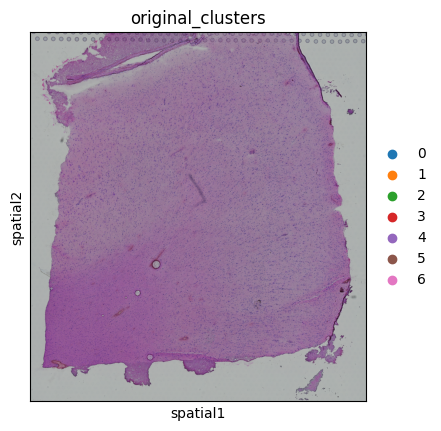

In [7]:
sc.pl.spatial(ad_target, color='original_clusters', spot_size=1.5)

0 of 3611
3610 of 3611


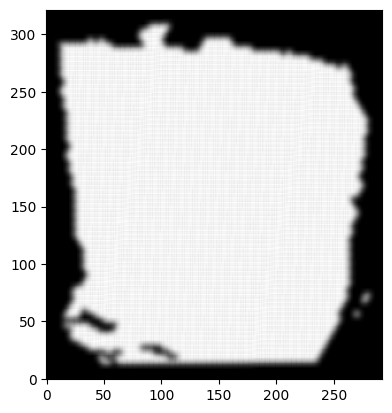

In [8]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 3596
3595 of 3596


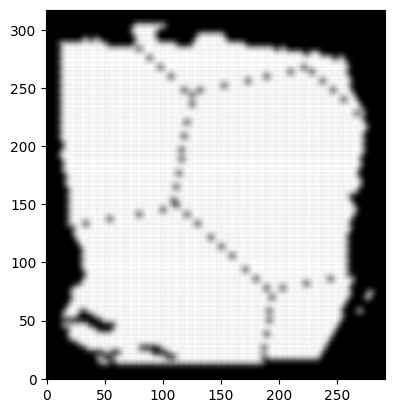

In [9]:
spatial_coords = ad_.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

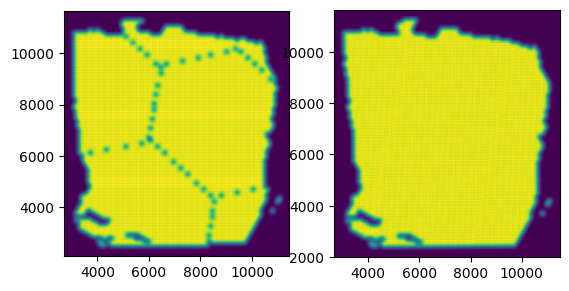

In [10]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 10min 45s, sys: 19.8 s, total: 11min 4s
Wall time: 10min 20s


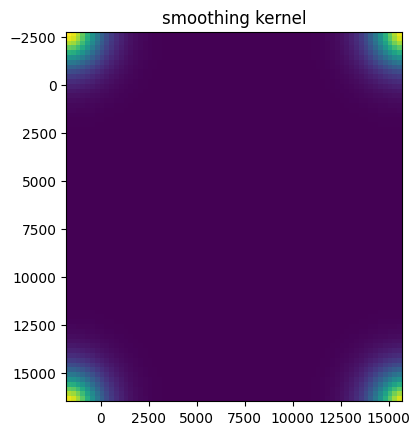

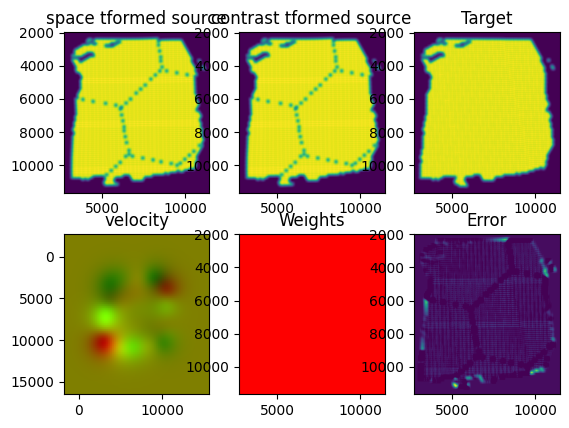

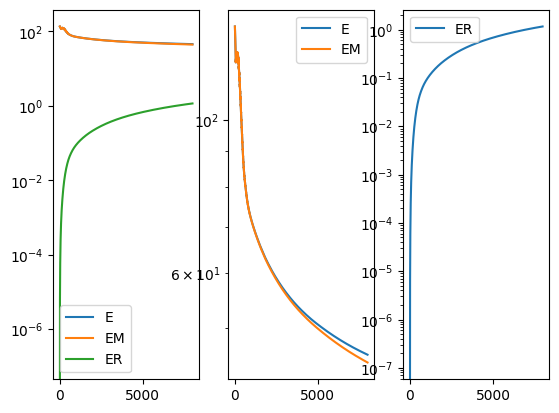

In [11]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            'niter': 8000,
            'device':device,
            'epV': 50,
            'sigmaA': 0.1, #standard deviation of artifact intensities
            'sigmaB': 0.1, #standard deviation of background intensities
            'sigmaM': 0.1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [75]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [123]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

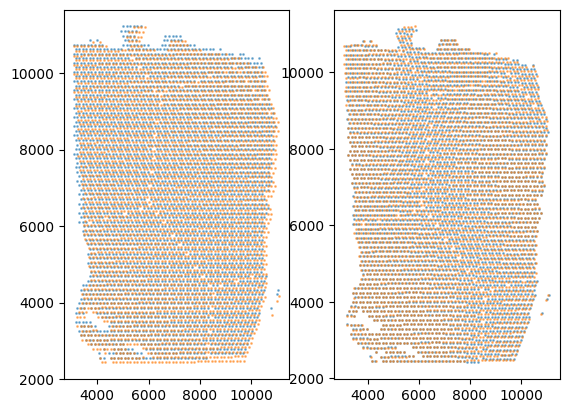

In [124]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [78]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [79]:
# Save as .pkl
alignment_df.to_pickle("151673_100_AlignmentPi.pkl")

## LAA

In [80]:
# LAA
#calculate laywise bar, result needs to be devided by total number to calculate the accuracy rate
def cal_layer_based_alignment_result(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    cnt1 = 0
    cnt2 = 0
    cnt3 = 0
    cnt4 = 0
    cnt5 = 0
    cnt6 = 0
    for i, elem in enumerate(alignment):
        if np.max(elem) - np.min(elem) != 0: # paste2 might have spots that are not aligned to any other spots. paste might have negative alignment
            if labels[i] == '-1' or labels[elem.argmax() + alignment.shape[0]] == '-1':
                continue
            if l_dict[labels[i]] == l_dict[labels[elem.argmax() + alignment.shape[0]]]:
                cnt0 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 1:
                cnt1 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 2:
                cnt2 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 3:
                cnt3 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 4:
                cnt4 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 5:
                cnt5 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 6:
                cnt6 += 1
    res.extend([cnt0, cnt1, cnt2, cnt3, cnt4, cnt5, cnt6])
    return res

In [ ]:
res = cal_layer_based_alignment_result(alignment, ad_, ad_target)
res

[664, 705, 701, 817, 257, 290, 177]

In [87]:
divisor = alignment.shape[0]
LAA_result = [num / divisor for num in res]
print(LAA_result)

[0.18388258100249238, 0.1952367765162005, 0.19412905012461923, 0.22625311548047633, 0.0711714206590972, 0.08031016338964275, 0.04901689282747161]


In [83]:
alignment.shape

(3611, 3596)

## ARI

In [89]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [90]:
ari = compute_alignment_ari(ad_target, ad_, alignment)
ari

0.9836251413182473

## Degree

In [135]:
def get_rotation_angle(R):
    # Extract the sine and cosine from the matrix
    cos_theta = R[0, 0]
    sin_theta = R[1, 0]

    # Compute the angle in radians
    theta = np.arctan2(sin_theta, cos_theta)

    # Convert the angle to degrees (optional)
    theta_deg = np.degrees(theta)

    return theta, theta_deg

In [136]:
# https://github.com/raphael-group/paste/blob/main/src/paste/visualization.py
X = np.array([x_target, y_target]).T
print(X.shape)
Y = np.array([x, y]).T
print(Y.shape)
print(alignment.shape)
tX = alignment.sum(axis=1).dot(X)
tY = alignment.sum(axis=0).dot(Y)
X = X - tX
Y = Y - tY
H = Y.T.dot(alignment.T.dot(X))
U, S, Vt = np.linalg.svd(H)
R = Vt.T.dot(U.T)

theta, theta_deg = get_rotation_angle(R)
theta_deg

(3611, 2)
(3596, 2)
(3611, 3596)


-1.0180808067849163

In [176]:
coordinatesB.shape[0]

739

In [180]:
import ot

coordinatesA = X
# coordinatesA = pd.read_csv('_overlap=100_align.csv')
coordinatesB = pd.read_csv('_overlap=100_align.csv')

# print(coordinatesA)
# print(coordinatesB)

coordinatesA = np.array(coordinatesA)
coordinatesB = np.array(coordinatesB)

disMatrix = ot.dist(coordinatesA, coordinatesB, metric='euclidean')
gt = pd.read_csv('./simData-20241219T155123Z-001/_overlap=100_mapping_matrix_ground_truth_spotIndex.csv', index_col=False)
gt = gt.iloc[:, 1:].reset_index(drop=True)
gt = gt.to_numpy()
s = (gt * disMatrix).sum()
# s
disPerSpot = s / coordinatesB.shape[0]
disPerSpot

155345.63752129365

In [144]:
gt_r_deg = [-1, -10.29, -17.48, -26.47, -38.3]
st_r_deg = [-1.0181, -4.5291, -1.3995, -4.7522, -2.8585]

# Convert to a NumPy array and create DataFrame
r_array = np.array(st_r_deg)[:, np.newaxis] # localOT_deg is the rotation degree of localOT
df = pd.DataFrame(r_array, columns=["localOT_r_deg"])
df['pair'] = range(len(st_r_deg))

# Calculate absolute differences and add as a new column
differences = np.abs(np.array(st_r_deg) - np.array(gt_r_deg))
df['dif_gt'] = differences

df

,localOT_r_deg,pair,dif_gt
0,-1.0181,0,0.0181
1,-4.5291,1,5.7609
2,-1.3995,2,16.0805
3,-4.7522,3,21.7178
4,-2.8585,4,35.4415


## 3D

In [ ]:
unique_clusters = ad_.obs['original_clusters']
for jjj in range(1, 2):
    unique_clusters = sorted(np.unique(
        np.concatenate([
            unique_clusters,
            ad_.obs['original_clusters']
        ])
    ))

In [ ]:
cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))
c_dict

{'0': '#1f77b4',
 '1': '#ff7f0e',
 '2': '#2ca02c',
 '3': '#d62728',
 '4': '#9467bd',
 '5': '#8c564b',
 '6': '#e377c2'}

In [ ]:
# only one slide
unique_clusters = ad_.obs['original_clusters']
for jjj in range(1, 2):
    unique_clusters = sorted(np.unique(
        np.concatenate([
            unique_clusters,
            ad_.obs['original_clusters']
        ])
    ))

cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))

coo = pd.DataFrame()

loc = pd.DataFrame(ad_.obsm['spatial'], columns=['X', 'Y'])
loc['Z'] = 1
loc['gt_labels'] = ad_.obs['original_clusters']
loc['celltype_colors'] = ad_.obs['original_clusters'].replace(dict(zip([0, 1, 2, 3, 4, 5, 6],cmap)))
coo = pd.concat([coo,loc],axis=0)

coords = coo.values[:,:3]
coo.to_csv('./simData-20241219T155123Z-001/simData/_gt_STalign_aligned_coordinates_colors.csv') # this file contains the original results: no need to swap XYZ

# XYZ coordinates can be swapped between each other for 3D plotting purporse, e.g.,:
# coords[:,[2, 0]] = coords[:,[0, 2]]
# coords[:,[1, 0]] = coords[:,[0, 1]]
# coords[:, 2] = -coords[:, 2]


In [ ]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

In [ ]:
dfs = ad_target.obs['original_clusters']
df0 = dfs.reset_index()
# df0.head()

df3_0 = pd.DataFrame(
    {
        "X": x_target,
        "Y": y_target,
    },
)

results = pd.concat([df0, df3_0], axis=1)
results['Z'] = 0
results['slice'] = 0
results

,index,original_clusters,X,Y,Z,slice
0,AAACAAGTATCTCCCA-1,3,9791,8468,0,0
1,AAACAATCTACTAGCA-1,1,5769,2807,0,0
2,AAACACCAATAACTGC-1,0,4068,9505,0,0
3,AAACAGAGCGACTCCT-1,3,9271,4151,0,0
4,AAACAGCTTTCAGAAG-1,5,3393,7583,0,0
...,...,...,...,...,...,...
3606,TTGTTTCACATCCAGG-1,0,5653,9396,0,0
3607,TTGTTTCATTAGTCTA-1,0,4825,9630,0,0
3608,TTGTTTCCATACAACT-1,6,4631,7831,0,0
3609,TTGTTTGTATTACACG-1,0,5571,11193,0,0


In [ ]:
dfs = ad_.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,AAACAAGTATCTCCCA-1,3
1,AAACAATCTACTAGCA-1,1
2,AAACACCAATAACTGC-1,0
3,AAACAGAGCGACTCCT-1,3
4,AAACAGCTTTCAGAAG-1,5


In [ ]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 1
results1['slice'] = 100
results1

,index,original_clusters,X,Y,Z,slice
0,AAACAAGTATCTCCCA-1,3,9807.196159,8447.111278,1,100
1,AAACAATCTACTAGCA-1,1,5761.502437,2811.499120,1,100
2,AAACACCAATAACTGC-1,0,4027.250357,9499.019895,1,100
3,AAACAGAGCGACTCCT-1,3,9332.963619,4192.218159,1,100
4,AAACAGCTTTCAGAAG-1,5,3394.730902,7589.580590,1,100
...,...,...,...,...,...,...
3591,TTGTTGTGTGTCAAGA-1,5,8072.137055,6222.676650,1,100
3592,TTGTTTCACATCCAGG-1,0,5646.256071,9345.060746,1,100
3593,TTGTTTCATTAGTCTA-1,0,4811.014031,9607.076747,1,100
3594,TTGTTTCCATACAACT-1,6,4608.111472,7816.411188,1,100


In [150]:
df3_1.to_csv("_overlap=100_align.csv", index=False)

In [ ]:
df = pd.concat([results, results1], axis=0)
df['celltype_colors'] = df['original_clusters'].replace(c_dict)
df

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,AAACAAGTATCTCCCA-1,3,9791.000000,8468.000000,0,0,#d62728
1,AAACAATCTACTAGCA-1,1,5769.000000,2807.000000,0,0,#ff7f0e
2,AAACACCAATAACTGC-1,0,4068.000000,9505.000000,0,0,#1f77b4
3,AAACAGAGCGACTCCT-1,3,9271.000000,4151.000000,0,0,#d62728
4,AAACAGCTTTCAGAAG-1,5,3393.000000,7583.000000,0,0,#8c564b
...,...,...,...,...,...,...,...
3591,TTGTTGTGTGTCAAGA-1,5,8072.137055,6222.676650,1,100,#8c564b
3592,TTGTTTCACATCCAGG-1,0,5646.256071,9345.060746,1,100,#1f77b4
3593,TTGTTTCATTAGTCTA-1,0,4811.014031,9607.076747,1,100,#1f77b4
3594,TTGTTTCCATACAACT-1,6,4608.111472,7816.411188,1,100,#e377c2


In [ ]:
df.to_csv("0.csv", index=False)